# 01 — Data Quality

**Data scope:** the development file (Jan–Oct 2013). The Nov–Dec test holdout is sealed and is
not present (`docs/decision_log.md`, D-002, D-106). This notebook checks data quality only; it
informs no feature or model choice.

**Goal:** establish whether the raw Kaggle *Flights* (2013, NYC departures) table is fit for a
pre-departure delay model: schema, dtypes, missing values, duplicates, invalid values, the
15-minute arrival-delay target, class balance, and which columns would leak post-departure
information.

All logic lives in `src/flight_delay/data/` (`load.py`, `validate.py`, `clean.py`, `schema.py`);
this notebook only calls it and displays results. Run top-to-bottom; no randomness is involved.

In [1]:
import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate the repo root (folder containing pyproject.toml) so the notebook runs from anywhere.
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from flight_delay.config import load_config  # noqa: E402

cfg = load_config(ROOT / "configs" / "config.yaml")
RAW_PATH = ROOT / cfg["paths"]["raw"]
THRESHOLD = cfg["target"]["threshold_minutes"]
POLICY = cfg["target"]["cancelled_policy"]

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Plot style: one accent hue, neutral ink, recessive grid.
ACCENT, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})

print("raw file :", RAW_PATH.relative_to(ROOT))
print("sha256   :", hashlib.sha256(RAW_PATH.read_bytes()).hexdigest())
print(f"target   : arr_delay >= {THRESHOLD} min | missing-label policy: {POLICY}")

raw file : data/interim/flights_dev.csv
sha256   : 8f206680eda4dc42098dbd4e9a6ec6f89f468afc41cbb913fd528fa4fc0018df
target   : arr_delay >= 15 min | missing-label policy: exclude


## 1. Load and schema

In [2]:
from flight_delay.data.load import load_dev_raw
from flight_delay.data.validate import validate_schema

df = load_dev_raw(cfg, ROOT)  # Jan-Oct development file; refuses any holdout row
print(f"rows = {len(df):,}   columns = {df.shape[1]}")
print("schema problems:", validate_schema(df) or "none")
df.head()

rows = 281,373   columns = 23
schema problems: none


,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name,date,sched_dep_dt
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.,2013-01-01,2013-01-01 05:15:00
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.,2013-01-01,2013-01-01 05:29:00
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.,2013-01-01,2013-01-01 05:40:00
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways,2013-01-01,2013-01-01 05:45:00
4,4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.,2013-01-01,2013-01-01 06:00:00


In [3]:
dtypes = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "example": df.iloc[0],
})
dtypes

,dtype,n_unique,example
id,int64,281373,0
year,int16,1,2013
month,int8,10,1
day,int8,31,1
dep_time,float64,1316,517.0
sched_dep_time,int16,1007,515
dep_delay,float64,515,2.0
arr_time,float64,1405,830.0
sched_arr_time,int16,1152,819
arr_delay,float64,566,11.0


In [4]:
print("date range :", df["date"].min().date(), "->", df["date"].max().date(),
      f"({df['date'].nunique()} distinct days)")
print("origins    :", sorted(df["origin"].unique()))
print("carriers   :", df["carrier"].nunique(), "| destinations:", df["dest"].nunique(),
      "| aircraft (tailnum):", df["tailnum"].nunique())
df.describe().T.round(1)

date range : 2013-01-01 -> 2013-10-31 (304 distinct days)
origins    : ['EWR', 'JFK', 'LGA']


carriers   : 16 | destinations: 104 | aircraft (tailnum): 3969


,count,mean,min,25%,50%,75%,max,std
id,281373.0,185083.53793,0.0,125746.0,196089.0,266432.0,336775.0,97814.747209
year,281373.0,2013.0,2013.0,2013.0,2013.0,2013.0,2013.0,0.0
month,281373.0,5.572009,1.0,3.0,6.0,8.0,10.0,2.847552
day,281373.0,15.750196,1.0,8.0,16.0,23.0,31.0,8.774625
dep_time,274376.0,1348.772181,1.0,907.0,1401.0,1745.0,2400.0,489.47147
sched_dep_time,281373.0,1344.433187,106.0,908.0,1359.0,1729.0,2359.0,467.634446
dep_delay,274376.0,12.959811,-33.0,-5.0,-2.0,11.0,1301.0,40.998895
arr_time,273972.0,1499.701192,1.0,1102.0,1534.0,1940.0,2400.0,534.075227
sched_arr_time,281373.0,1534.881741,1.0,1122.0,1555.0,1945.0,2359.0,497.921013
arr_delay,273355.0,6.741907,-86.0,-17.0,-5.0,13.0,1272.0,45.471364


## 2. Column roles and leakage

The decision time is **before departure**. Any column only observable after the aircraft leaves
the gate is excluded from features. The post-departure list comes from
`features/leakage.py` (single source of truth); `schema.py` assigns every raw column a role.

In [5]:
from flight_delay.data.schema import column_roles

column_roles()

,column,role,allowed_as_feature
0,air_time,post-departure,False
1,arr_delay,target source (post-departure),False
2,arr_time,post-departure,False
3,carrier,pre-departure,True
4,day,pre-departure,True
5,dep_delay,post-departure,False
6,dep_time,post-departure,False
7,dest,pre-departure,True
8,distance,pre-departure,True
9,flight,pre-departure,True


**How strong is the leak?** Scoring each post-departure field on its own against the target
(on completed flights) shows why they must be removed: a model with access to them would look
excellent offline and be useless at decision time.

In [6]:
from sklearn.metrics import roc_auc_score

from flight_delay.data.clean import add_flight_status, add_target
from flight_delay.features.leakage import POST_DEPARTURE_COLUMNS

lab = add_target(add_flight_status(df), THRESHOLD)
done = lab[lab["is_delayed"].notna()]
leak_auc = pd.Series(
    {c: roc_auc_score(done["is_delayed"].astype(int), done[c])
     for c in sorted(POST_DEPARTURE_COLUMNS - {"arr_delay"})},
    name="single-feature ROC AUC",
).round(3)
leak_auc.to_frame()

,single-feature ROC AUC
air_time,0.498
arr_time,0.605
dep_delay,0.898
dep_time,0.672


## 3. Missing values

In [7]:
from flight_delay.data.validate import missing_patterns, missing_summary

ms = missing_summary(df)
ms[ms["n_missing"] > 0]

,n_missing,pct_missing
arr_delay,8018,2.850
air_time,8018,2.850
arr_time,7401,2.630
dep_time,6997,2.487
dep_delay,6997,2.487
tailnum,2169,0.771


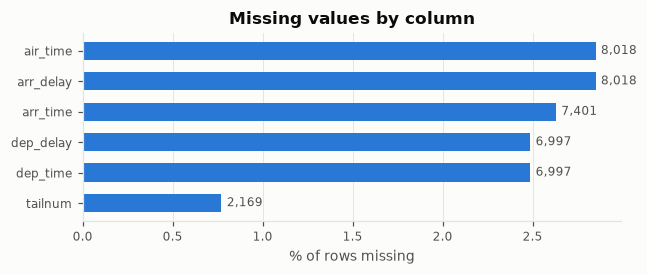

In [8]:
nz = ms[ms["n_missing"] > 0].sort_values("n_missing")
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(nz.index, nz["pct_missing"], color=ACCENT, height=0.6)
for y, (n, p) in enumerate(zip(nz["n_missing"], nz["pct_missing"])):
    ax.text(p + 0.03, y, f"{n:,}", va="center", fontsize=8, color=MUTED)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values by column")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Missingness is structured rather than random — the actual-time fields go missing together:

In [9]:
missing_patterns(df, ["dep_time", "dep_delay", "arr_time", "arr_delay", "air_time", "tailnum"])

,dep_time,dep_delay,arr_time,arr_delay,air_time,tailnum,n_rows
0,False,False,False,False,False,False,273355
1,True,True,True,True,True,False,4828
2,True,True,True,True,True,True,2169
3,False,False,False,True,True,False,617
4,False,False,True,True,True,False,404


In [10]:
# Is tailnum missingness tied to cancellation?
pd.crosstab(df["tailnum"].isna().rename("tailnum missing"),
            df["dep_time"].isna().rename("dep_time missing (cancelled)"))

dep_time missing (cancelled),False,True
tailnum missing,,
False,274376,4828
True,0,2169


## 4. Duplicates

In [11]:
from flight_delay.data.validate import NATURAL_KEY, duplicate_summary

print("natural key:", NATURAL_KEY)
duplicate_summary(df)

natural key: ['year', 'month', 'day', 'carrier', 'flight', 'origin', 'sched_dep_time']


{'exact_duplicate_rows': 0, 'duplicate_natural_key': 0, 'duplicate_id': 0}

## 5. Invalid and inconsistent values

Rule-based checks. `error` = impossible or internally inconsistent; `info` = valid but unusual.
Delay consistency is checked modulo 24 h because times are clock times (`HHMM`) and flights can
depart or arrive after midnight.

In [12]:
from flight_delay.data.validate import invalid_value_report

report = invalid_value_report(df)
report

,check,kind,n_violations,pct
0,dep_time: malformed HHMM,error,0,0.0000
1,sched_dep_time: malformed HHMM,error,0,0.0000
2,arr_time: malformed HHMM,error,0,0.0000
3,sched_arr_time: malformed HHMM,error,0,0.0000
4,month not in 1..12,error,0,0.0000
5,invalid calendar date,error,0,0.0000
6,hour/minute != sched_dep_time,error,0,0.0000
7,distance <= 0,error,0,0.0000
8,air_time <= 0,error,0,0.0000
9,origin == dest,error,0,0.0000


In [13]:
print("error-level violations:", report.loc[report["kind"] == "error", "n_violations"].sum())

# The largest departure delays are next-day departures, not data errors:
cols = ["date", "carrier", "flight", "origin", "dest", "sched_dep_time", "dep_time", "dep_delay", "arr_delay"]
df.nlargest(5, "dep_delay")[cols]

error-level violations: 0


,date,carrier,flight,origin,dest,sched_dep_time,dep_time,dep_delay,arr_delay
7072,2013-01-09,HA,51,JFK,HNL,900,641.0,1301.0,1272.0
180375,2013-06-15,MQ,3535,JFK,CMH,1935,1432.0,1137.0,1127.0
8239,2013-01-10,MQ,3695,EWR,ORD,1635,1121.0,1126.0,1109.0
271640,2013-09-20,AA,177,JFK,SFO,1845,1139.0,1014.0,1007.0
214973,2013-07-22,MQ,3075,JFK,CVG,1600,845.0,1005.0,989.0


In [14]:
# Routes with more than one distance, and the single EWR->LGA row
multi = df.groupby(["origin", "dest"])["distance"].unique()
display(multi[multi.str.len() > 1].to_frame("distances"))
df.loc[df["dest"] == "LGA", ["date", "carrier", "flight", "origin", "dest", "distance", "dep_time"]]

,,distances
origin,dest,
EWR,EGE,"[1726, 1725]"
JFK,EGE,"[1747, 1746]"


,date,carrier,flight,origin,dest,distance,dep_time
220542,2013-07-27,US,1632,EWR,LGA,17,NaN


## 6. Flight status (cancelled / no arrival record)

In [15]:
status = lab["flight_status"].value_counts().to_frame("n")
status["share_%"] = (100 * status["n"] / len(lab)).round(2)
status

,n,share_%
flight_status,,
completed,273355,97.15
cancelled,6997,2.49
departed_no_arrival_delay,1021,0.36


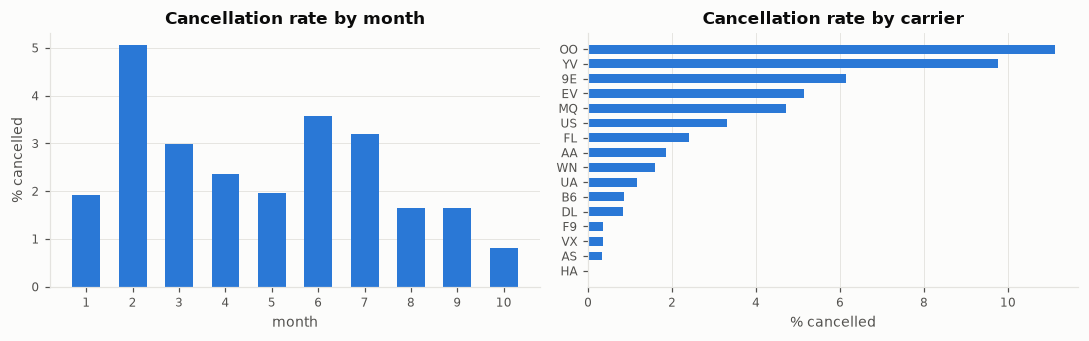

In [16]:
cancel = lab["flight_status"].eq("cancelled")
by_month = cancel.groupby(lab["month"]).mean() * 100
by_carrier = (cancel.groupby(lab["carrier"]).mean() * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(by_month.index, by_month.values, color=ACCENT, width=0.6)
axes[0].set_xticks(by_month.index)
axes[0].set_xlabel("month")
axes[0].set_ylabel("% cancelled")
axes[0].set_title("Cancellation rate by month")
axes[0].grid(axis="x", visible=False)
axes[1].barh(by_carrier.index, by_carrier.values, color=ACCENT, height=0.6)
axes[1].set_xlabel("% cancelled")
axes[1].set_title("Cancellation rate by carrier")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 7. Target: arrival delay ≥ 15 minutes

`is_delayed = 1` if `arr_delay >= 15` (BTS on-time convention), else 0. `arr_delay` is in minutes
and is internally consistent with `arr_time − sched_arr_time` (check in §5). Rows without
`arr_delay` (cancelled or no arrival record) get a missing label and are then resolved by the
policy in `configs/config.yaml` (`exclude` by default; `delayed` is the alternative).

In [17]:
print(df["arr_delay"].describe(percentiles=[.01, .05, .25, .5, .75, .9, .95, .99]).round(1))
print(f"\nshare exactly at threshold (arr_delay == {THRESHOLD}):",
      f"{(df['arr_delay'] == THRESHOLD).mean():.4%}")

count    273355.0
mean          6.7
std          45.5
min         -86.0
1%          -45.0
5%          -33.0
25%         -17.0
50%          -5.0
75%          13.0
90%          53.0
95%          94.0
99%         193.0
max        1272.0
Name: arr_delay, dtype: float64

share exactly at threshold (arr_delay == 15): 0.7165%


In [18]:
from flight_delay.data.clean import handle_cancelled
from flight_delay.data.validate import class_balance

print("Before resolving missing labels:")
display(class_balance(lab["is_delayed"]))
for policy in ["exclude", "delayed"]:
    y = handle_cancelled(lab, policy)["is_delayed"]
    print(f"policy={policy!r}: n={len(y):,}  positive rate={y.mean():.4f}  "
          f"imbalance ratio (neg:pos)={(1 - y.mean()) / y.mean():.2f}:1")

Before resolving missing labels:


,n,share
is_delayed,,
0,207201,0.7364
1,66154,0.2351
missing,8018,0.0285


policy='exclude': n=273,355  positive rate=0.2420  imbalance ratio (neg:pos)=3.13:1
policy='delayed': n=281,373  positive rate=0.2636  imbalance ratio (neg:pos)=2.79:1


In [19]:
labelled = handle_cancelled(lab, POLICY)
monthly = labelled.groupby("month")["is_delayed"].agg(["size", "mean"]).rename(
    columns={"size": "n", "mean": "delay_rate"})
monthly["delay_rate"] = monthly["delay_rate"].astype(float).round(4)
monthly.T

month,1,2,3,4,5,6,7,8,9,10
n,26398,23611,27902,27564,28128,27075,28293,28756,27010,28618
delay_rate,0.2349,0.2378,0.236,0.2875,0.2267,0.3152,0.3221,0.246,0.1372,0.1756


Because the split is chronological (train Jan–Aug, valid Sep–Oct, test Nov–Dec in the config),
the positive rate per split matters for PR-AUC baselines. The test split is sealed, so only train
and validation are shown:

In [20]:
split_rate = {}
for name, (start, end) in cfg["split"].items():
    m = labelled["date"].between(start, end)
    if not m.any():  # test split: sealed, not in the development data
        continue
    split_rate[name] = {"n": int(m.sum()), "positive_rate": round(float(labelled.loc[m, "is_delayed"].mean()), 4)}
pd.DataFrame(split_rate).T

,n,positive_rate
train,217727.0,0.2637
valid,55628.0,0.1570


## 8. Leakage-safe view

In [21]:
from flight_delay.data.schema import pre_departure_view
from flight_delay.features.leakage import assert_no_leakage

safe = pre_departure_view(labelled)
assert_no_leakage(safe.columns)
print("columns kept:", list(safe.columns))
print("shape:", safe.shape)

columns kept: ['year', 'month', 'day', 'sched_dep_time', 'sched_arr_time', 'carrier', 'flight', 'origin', 'dest', 'distance', 'hour', 'minute', 'time_hour', 'name', 'date', 'sched_dep_dt', 'is_delayed']
shape: (273355, 17)


## Findings (from the outputs above)

**Data:** development file only (Jan–Oct 2013). The Nov–Dec test holdout is sealed and not inspected.

**Coverage and schema**
- 281,373 flights × 21 raw columns, every day from 2013-01-01 to 2013-10-31 (304 days), departing EWR, JFK and LGA only; 16 carriers, 104 destinations, 3,969 tail numbers. Schema matches the expected columns and dtypes.
- `id` is a row identifier and is **not** sorted by date, so it is not used for ordering or as a feature.

**Missing values** are confined to the actual-time fields and `tailnum`, and follow three structured patterns:
- 6,997 rows (2.49%) have no `dep_time` → treated as **cancelled**.
- 1,021 rows (0.36%) departed but have no `arr_delay` (617 of them still have an `arr_time`) → labelled `departed_no_arrival_delay`. These are *probably* diversions, but the dataset has no diversion flag, so this is an assumption.
- `tailnum` is missing for 2,169 rows, **all of them cancelled flights**. Its missingness therefore encodes the outcome, which is why `tailnum` is marked "caution" and excluded from the leakage-safe view.

**Duplicates:** none — 0 exact duplicate rows, 0 duplicates on the natural key, 0 duplicate ids.

**Invalid values:** 0 error-level violations. All HHMM times are well formed; `dep_delay` and `arr_delay` agree with actual − scheduled clock time once midnight wrap-around is allowed. Unusual-but-valid cases:
- 24 departures delayed > 12 h (max 1,301 min) — next-day departures, consistent with their times.
- `2400` is used for midnight in 22 `dep_time` and 124 `arr_time` values.
- 188 flights arrive more than 1 h early; 31 arrive more than 10 h late.
- 295 flights imply < 150 mph average speed (mostly short hops) and 2 imply > 650 mph; kept but noted.
- EWR→EGE and JFK→EGE each carry two distances 1 mile apart (187 rows).
- One cancelled US Airways flight EWR→LGA (17 miles) — a repositioning-type record; it drops out under the `exclude` policy.

**Cancellations** vary by month (highest in February, 5.1%; lowest in October, 0.8%) and by carrier (0% for HA to ~10–11% for YV and OO, which have few flights), so the `exclude` vs `delayed` choice changes the label distribution across groups.

**Target (`arr_delay >= 15`):**
- Completed flights: 273,355; positive rate **24.2%**, i.e. about **3.1 : 1** negatives to positives. Under the `delayed` policy, the rate becomes 26.4% (2.8 : 1).
- 0.72% of flights have `arr_delay` exactly 15 and are therefore positive; the boundary is inclusive by construction.
- `arr_delay` is heavily right-skewed: median −5 min, 90th percentile 53 min, 99th percentile 193 min.

**Leakage:** `dep_delay` alone reaches a single-feature ROC AUC of **0.898** against the target, and `dep_time` 0.672 (part of that comes from the scheduled hour it implies). These columns, plus `arr_time`, `air_time` and `arr_delay`, are removed by `pre_departure_view`; `assert_no_leakage` passes on the resulting 17-column frame.

**Class balance across the configured chronological split** is uneven: train (Jan–Aug) 26.4%, validation (Sep–Oct) **15.7%**. September (13.7%) and October (17.6%) are the quietest months in the development data, so thresholds and calibration fitted on validation may transfer poorly. The split dates are kept (`docs/decision_log.md`, D-013) and this is reported as a limitation.

## Assumptions and limitations
- Cancelled = missing `dep_time`; "no arrival delay" = departed but missing `arr_delay`. Neither label is given by the data source.
- Default policy is `exclude` (from `configs/config.yaml`): the model will estimate P(delay ≥ 15 min | flight operates and arrival is recorded). It does not predict cancellations.
- All times are **local** clock times; `sched_arr_time` is in destination local time and the dataset has no time-zone column, so scheduled block time cannot be computed from these two fields without external airport time-zone data.
- Only NYC departures from a single year: results may not generalise to other airports or years, and there is no weather, aircraft or crew information.
